# Práctica 1: Árboles de Decisión con Datos Sintéticos

**Machine Learning 1 — FIUNA**

**Docente:** Diego Stalder | **Práctica:** Carlos Benítez

---

## Objetivo

Experimentar con **Árboles de Decisión** usando datasets sintéticos controlados para:

1. **Visualizar** cómo un árbol divide el espacio de decisión
2. **Comparar** las métricas Gini, Entropía y Error de clasificación
3. **Analizar** el efecto de la profundidad en el sobreajuste
4. **Implementar** poda (pre-poda y post-poda)
5. **Interpretar** la importancia de características

## Datasets sintéticos

| Dataset | Forma | Propósito |
|---------|-------|-----------|
| `moons` | Dos lunas entrelazadas | Frontera no lineal clásica |
| `circles` | Círculos concéntricos | Requiere transformación radial |
| `blobs` | Clusters gaussianos | Caso separable linealmente |
| `xor` | Patrón XOR | Frontera no lineal muy simple |
| `spiral` | Espirales entrelazadas | Caso muy difícil para árboles |

## 0. Importaciones y Configuración

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time

from sklearn.datasets import make_moons, make_circles, make_blobs, make_classification
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, validation_curve
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

import warnings
warnings.filterwarnings('ignore')

# Configuración visual
plt.rcParams.update({
    'figure.figsize': (10, 6),
    'font.size': 11,
    'axes.grid': True,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'figure.dpi': 100
})
sns.set_palette('husl')
np.random.seed(42)

print("="*80)
print("🌳 PRÁCTICA: ÁRBOLES DE DECISIÓN CON DATOS SINTÉTICOS")
print("="*80)

🌳 PRÁCTICA: ÁRBOLES DE DECISIÓN CON DATOS SINTÉTICOS


## 1. Generación de Datasets Sintéticos

Generamos 5 datasets con diferentes formas geométricas.

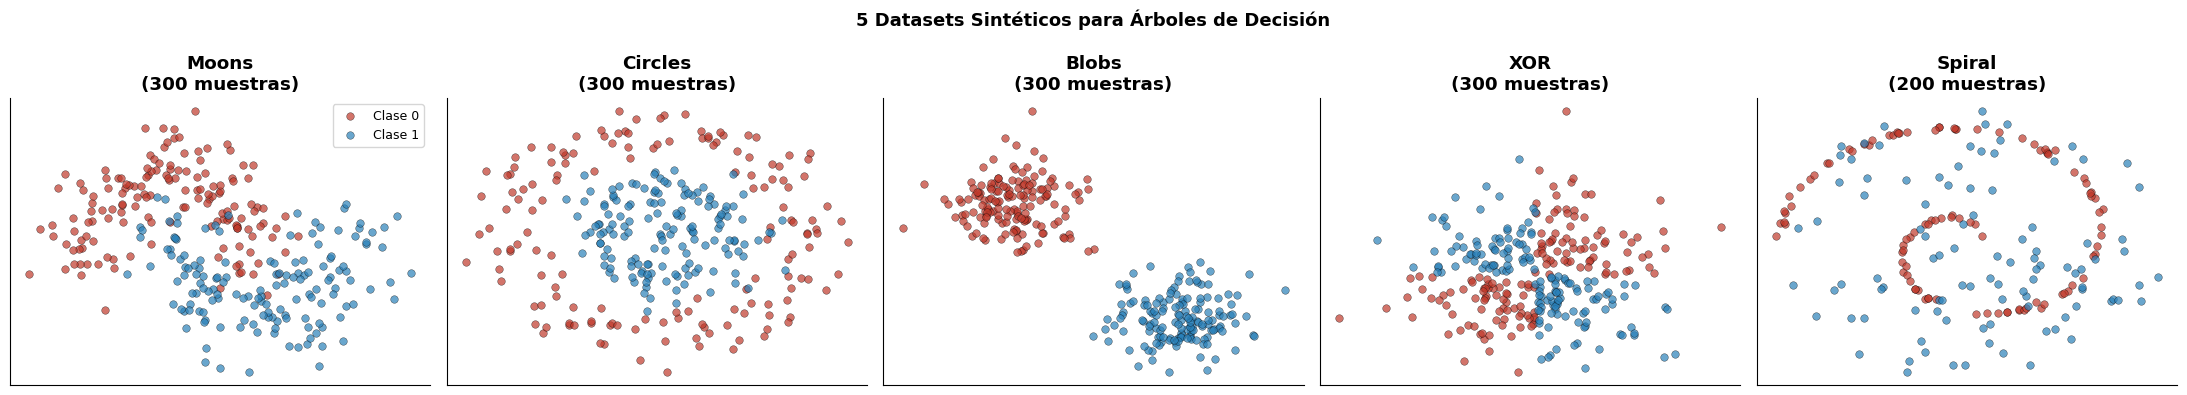

In [2]:
# Generar datasets sintéticos
np.random.seed(42)

datasets = {}

# 1. Moons
X_moons, y_moons = make_moons(n_samples=300, noise=0.25, random_state=42)
datasets['Moons'] = (X_moons, y_moons)

# 2. Circles
X_circ, y_circ = make_circles(n_samples=300, factor=0.4, noise=0.15, random_state=42)
datasets['Circles'] = (X_circ, y_circ)

# 3. Blobs
X_blobs, y_blobs = make_blobs(n_samples=300, centers=2, cluster_std=1.5, random_state=42)
datasets['Blobs'] = (X_blobs, y_blobs)

# 4. XOR
np.random.seed(42)
X_xor = np.random.randn(300, 2) * 0.5
y_xor = ((X_xor[:, 0] > 0) ^ (X_xor[:, 1] > 0)).astype(int)
datasets['XOR'] = (X_xor, y_xor)

# 5. Spiral
def make_spiral(n_samples=200, noise=0.1):
    np.random.seed(42)
    n = n_samples // 2
    theta = np.sqrt(np.random.rand(n)) * 3 * np.pi
    r = theta
    X1 = np.c_[r * np.cos(theta), r * np.sin(theta)]
    y1 = np.zeros(n)
    theta2 = np.sqrt(np.random.rand(n)) * 3 * np.pi
    X2 = np.c_[r * np.cos(theta2 + np.pi), r * np.sin(theta2 + np.pi)]
    y2 = np.ones(n)
    X = np.vstack([X1, X2]) + np.random.randn(2*n, 2) * noise
    y = np.hstack([y1, y2])
    return X, y.astype(int)

X_spiral, y_spiral = make_spiral()
datasets['Spiral'] = (X_spiral, y_spiral)

# Visualizar todos los datasets
fig, axes = plt.subplots(1, 5, figsize=(22, 4))
for ax, (name, (X, y)) in zip(axes, datasets.items()):
    ax.scatter(X[y==0, 0], X[y==0, 1], c='#C0392B', s=30, edgecolor='k',
               linewidth=0.3, alpha=0.7, label='Clase 0')
    ax.scatter(X[y==1, 0], X[y==1, 1], c='#2980B9', s=30, edgecolor='k',
               linewidth=0.3, alpha=0.7, label='Clase 1')
    ax.set_title(f'{name}\n({len(X)} muestras)', fontweight='bold')
    ax.set_xticks([])
    ax.set_yticks([])
    if name == 'Moons':
        ax.legend(loc='upper right', fontsize=9)

plt.suptitle('5 Datasets Sintéticos para Árboles de Decisión', fontweight='bold', fontsize=13)
plt.tight_layout()
plt.show()

## 2. Visualización de Fronteras de Decisión por Profundidad

Analizamos cómo cambia la frontera al aumentar la profundidad del árbol.

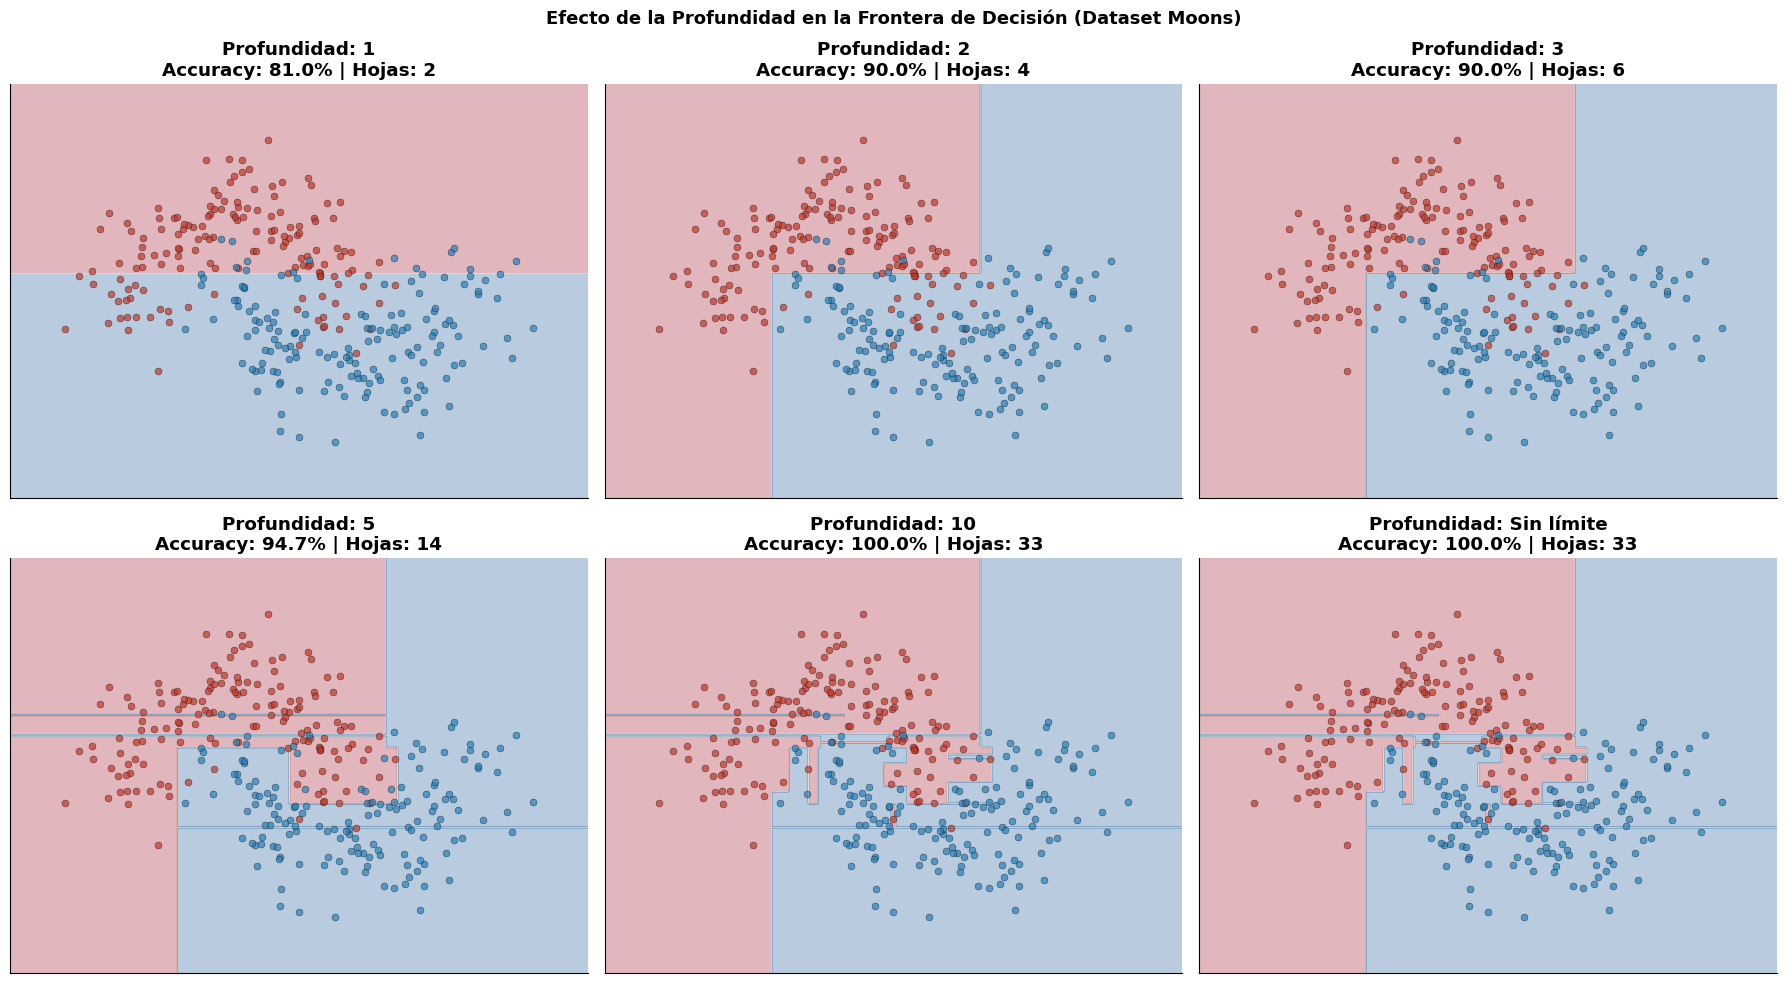

🌳 Observaciones:
   - Profundidad 1: frontera muy simple (subajuste)
   - Profundidad 3-5: buen balance sesgo-varianza
   - Sin límite: sobreajuste (frontera muy irregular)


In [3]:
# Visualización de fronteras con diferentes profundidades
X_viz, y_viz = datasets['Moons']

profundidades = [1, 2, 3, 5, 10, None]
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

xx, yy = np.meshgrid(np.linspace(X_viz[:,0].min()-0.5, X_viz[:,0].max()+0.5, 300),
                     np.linspace(X_viz[:,1].min()-0.5, X_viz[:,1].max()+0.5, 300))

for ax, depth in zip(axes.ravel(), profundidades):
    tree = DecisionTreeClassifier(max_depth=depth, random_state=42)
    tree.fit(X_viz, y_viz)
    
    Z = tree.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    acc = tree.score(X_viz, y_viz)
    
    ax.contourf(xx, yy, Z, alpha=0.3, cmap='RdBu')
    ax.scatter(X_viz[y_viz==0, 0], X_viz[y_viz==0, 1],
               c='#C0392B', s=25, edgecolor='k', linewidth=0.3, alpha=0.7)
    ax.scatter(X_viz[y_viz==1, 0], X_viz[y_viz==1, 1],
               c='#2980B9', s=25, edgecolor='k', linewidth=0.3, alpha=0.7)
    
    depth_str = str(depth) if depth else 'Sin límite'
    ax.set_title(f'Profundidad: {depth_str}\nAccuracy: {acc*100:.1f}% | Hojas: {tree.get_n_leaves()}',
                 fontweight='bold')
    ax.set_xticks([])
    ax.set_yticks([])

plt.suptitle('Efecto de la Profundidad en la Frontera de Decisión (Dataset Moons)',
             fontweight='bold', fontsize=13)
plt.tight_layout()
plt.show()

print("🌳 Observaciones:")
print("   - Profundidad 1: frontera muy simple (subajuste)")
print("   - Profundidad 3-5: buen balance sesgo-varianza")
print("   - Sin límite: sobreajuste (frontera muy irregular)")

## 3. Comparación de Métricas: Gini vs Entropía

Comparamos el desempeño del árbol usando diferentes métricas de impureza.

📊 COMPARACIÓN: GINI VS ENTROPÍA (profundidad 5)

Accuracy en TEST:
Métrica  entropy    gini
Dataset                 
Blobs     1.0000  1.0000
Circles   0.9667  0.9444
Moons     0.8889  0.9333
Spiral    0.6167  0.6667
XOR       0.5444  0.5444

Accuracy en TRAIN:
Métrica  entropy    gini
Dataset                 
Blobs     1.0000  1.0000
Circles   0.9714  0.9714
Moons     0.9476  0.9619
Spiral    0.7071  0.7357
XOR       0.6476  0.6476

Diferencia (Train - Test): sobreajuste
Métrica  entropy    gini
Dataset                 
Blobs     0.0000  0.0000
Circles   0.0048  0.0270
Moons     0.0587  0.0286
Spiral    0.0905  0.0690
XOR       0.1032  0.1032


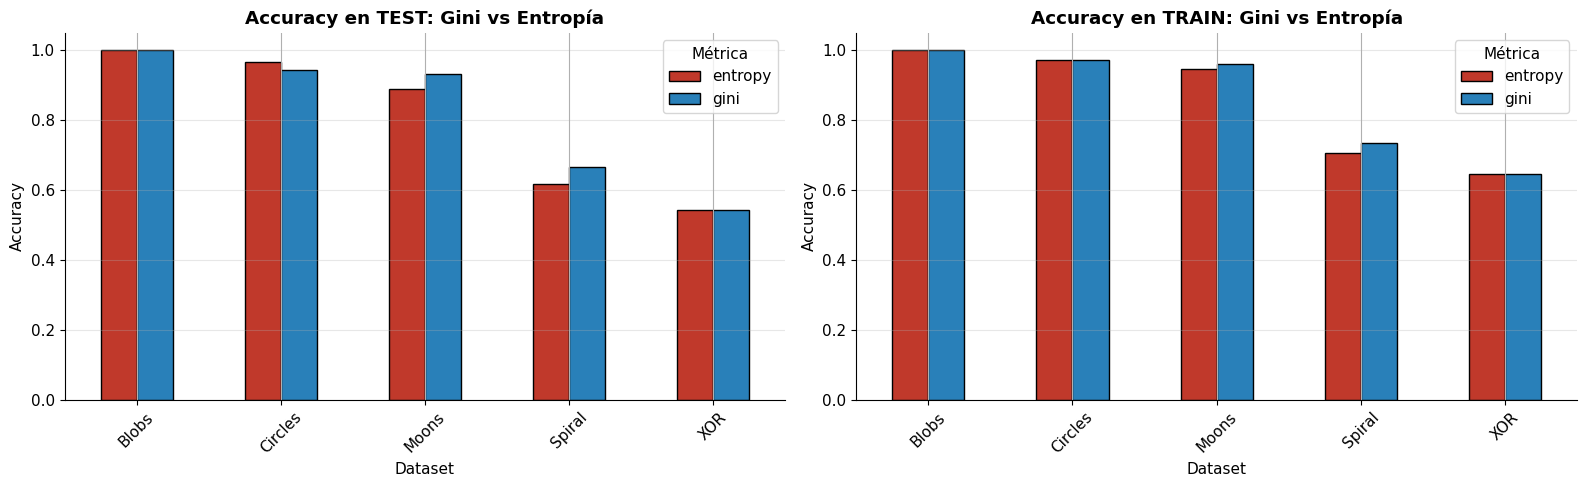

In [4]:
# Comparar Gini vs Entropía en todos los datasets
resultados_metricas = []

for nombre, (X, y) in datasets.items():
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, random_state=42)
    
    for metrica in ['gini', 'entropy']:
        tree = DecisionTreeClassifier(criterion=metrica, max_depth=5, random_state=42)
        tree.fit(X_tr, y_tr)
        
        acc_tr = accuracy_score(y_tr, tree.predict(X_tr))
        acc_te = accuracy_score(y_te, tree.predict(X_te))
        
        resultados_metricas.append({
            'Dataset': nombre,
            'Métrica': metrica,
            'Accuracy Train': acc_tr,
            'Accuracy Test': acc_te,
            'Profundidad real': tree.get_depth(),
            'Hojas': tree.get_n_leaves()
        })

df_metricas = pd.DataFrame(resultados_metricas)

# Pivot para comparación
pivot_test = df_metricas.pivot(index='Dataset', columns='Métrica', values='Accuracy Test')
pivot_train = df_metricas.pivot(index='Dataset', columns='Métrica', values='Accuracy Train')

print("="*80)
print("📊 COMPARACIÓN: GINI VS ENTROPÍA (profundidad 5)")
print("="*80)
print("\nAccuracy en TEST:")
print(pivot_test.round(4))
print("\nAccuracy en TRAIN:")
print(pivot_train.round(4))
print("\nDiferencia (Train - Test): sobreajuste")
print((pivot_train - pivot_test).round(4))

# Visualización
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

pivot_test.plot(kind='bar', ax=axes[0], color=['#C0392B', '#2980B9'], edgecolor='k')
axes[0].set_title('Accuracy en TEST: Gini vs Entropía', fontweight='bold')
axes[0].set_ylabel('Accuracy')
axes[0].legend(title='Métrica')
axes[0].grid(alpha=0.3, axis='y')
axes[0].tick_params(axis='x', rotation=45)

pivot_train.plot(kind='bar', ax=axes[1], color=['#C0392B', '#2980B9'], edgecolor='k')
axes[1].set_title('Accuracy en TRAIN: Gini vs Entropía', fontweight='bold')
axes[1].set_ylabel('Accuracy')
axes[1].legend(title='Métrica')
axes[1].grid(alpha=0.3, axis='y')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

## 4. Análisis de Sobreajuste: Curvas de Validación

Graficamos la accuracy en train y test en función de la profundidad para **visualizar el sobreajuste**.

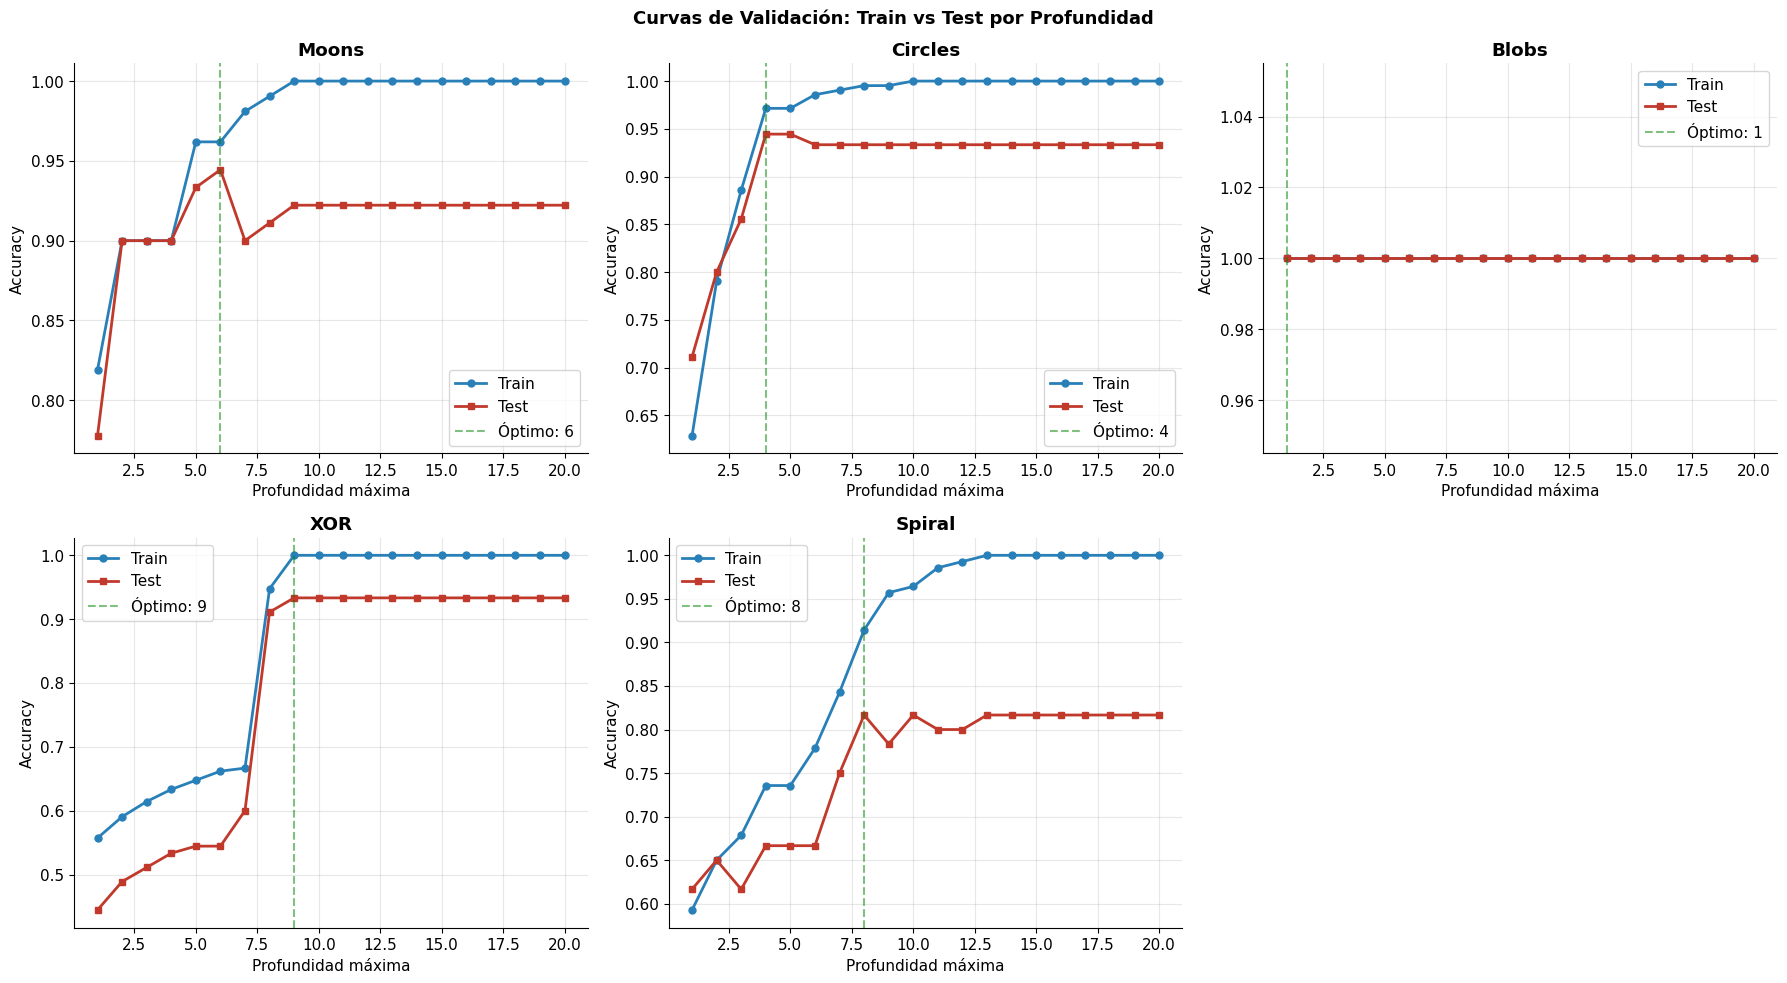

🌳 Observaciones:
   - Train accuracy siempre crece con la profundidad (sobreajuste)
   - Test accuracy sube al principio y luego baja
   - El punto óptimo es donde Test es máximo


In [5]:
# Curvas de validación para cada dataset
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
profundidades = range(1, 21)

for ax, (nombre, (X, y)) in zip(axes.ravel(), datasets.items()):
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, random_state=42)
    
    train_accs, test_accs = [], []
    for d in profundidades:
        tree = DecisionTreeClassifier(max_depth=d, random_state=42)
        tree.fit(X_tr, y_tr)
        train_accs.append(accuracy_score(y_tr, tree.predict(X_tr)))
        test_accs.append(accuracy_score(y_te, tree.predict(X_te)))
    
    ax.plot(profundidades, train_accs, 'o-', color='#2980B9', linewidth=2, markersize=5, label='Train')
    ax.plot(profundidades, test_accs, 's-', color='#C0392B', linewidth=2, markersize=5, label='Test')
    ax.set_title(f'{nombre}', fontweight='bold')
    ax.set_xlabel('Profundidad máxima')
    ax.set_ylabel('Accuracy')
    ax.legend()
    ax.grid(alpha=0.3)
    
    # Marcar la mejor profundidad
    best_d = profundidades[np.argmax(test_accs)]
    ax.axvline(x=best_d, color='green', linestyle='--', alpha=0.5, label=f'Óptimo: {best_d}')
    ax.legend()

axes.ravel()[-1].axis('off')
plt.suptitle('Curvas de Validación: Train vs Test por Profundidad', fontweight='bold', fontsize=13)
plt.tight_layout()
plt.show()

print("🌳 Observaciones:")
print("   - Train accuracy siempre crece con la profundidad (sobreajuste)")
print("   - Test accuracy sube al principio y luego baja")
print("   - El punto óptimo es donde Test es máximo")

## 5. Pre-poda: Optimización de Hiperparámetros

La **pre-poda** limita el crecimiento del árbol mediante parámetros como:
- `max_depth`: profundidad máxima
- `min_samples_split`: mínimo de muestras para dividir
- `min_samples_leaf`: mínimo de muestras en hoja
- `max_features`: máximo de características a considerar

In [6]:
# GridSearchCV con pre-poda
X_tr, X_te, y_tr, y_te = train_test_split(X_moons, y_moons, test_size=0.3, random_state=42)

param_grid = {
    'max_depth': [2, 3, 5, 7, 10, None],
    'min_samples_split': [2, 5, 10, 20],
    'min_samples_leaf': [1, 2, 5, 10],
    'criterion': ['gini', 'entropy']
}

tree_base = DecisionTreeClassifier(random_state=42)
grid = GridSearchCV(tree_base, param_grid, cv=5, scoring='accuracy', n_jobs=-1)
grid.fit(X_tr, y_tr)

print("="*80)
print("📊 GRIDSEARCHCV: MEJOR CONFIGURACIÓN DE PRE-PODA")
print("="*80)
print(f"Mejores hiperparámetros: {grid.best_params_}")
print(f"Mejor accuracy en CV:    {grid.best_score_*100:.2f}%")
print(f"Accuracy en test:        {grid.score(X_te, y_te)*100:.2f}%")

# Comparar con árbol sin restricciones
tree_full = DecisionTreeClassifier(random_state=42)
tree_full.fit(X_tr, y_tr)
print(f"\nComparación:")
print(f"   Árbol sin restricciones (train/test): {tree_full.score(X_tr, y_tr)*100:.2f}% / {tree_full.score(X_te, y_te)*100:.2f}%")
print(f"   Árbol con pre-poda óptima (train/test): {grid.score(X_tr, y_tr)*100:.2f}% / {grid.score(X_te, y_te)*100:.2f}%")

📊 GRIDSEARCHCV: MEJOR CONFIGURACIÓN DE PRE-PODA
Mejores hiperparámetros: {'criterion': 'entropy', 'max_depth': 7, 'min_samples_leaf': 1, 'min_samples_split': 2}
Mejor accuracy en CV:    90.00%
Accuracy en test:        87.78%

Comparación:
   Árbol sin restricciones (train/test): 100.00% / 92.22%
   Árbol con pre-poda óptima (train/test): 99.05% / 87.78%


## 6. Post-poda: Cost Complexity Pruning (CCP)

La **post-poda** construye el árbol completo y luego elimina ramas que no aportan. Scikit-learn implementa el **Cost Complexity Pruning**:

$$R_\alpha(T) = R(T) + \alpha \cdot |T|$$

Donde $R(T)$ es el error de clasificación y $|T|$ el número de hojas. El parámetro $\alpha$ controla el trade-off.

Número de valores de alpha generados: 13
Rango de alpha: [0.000000, 0.072299]


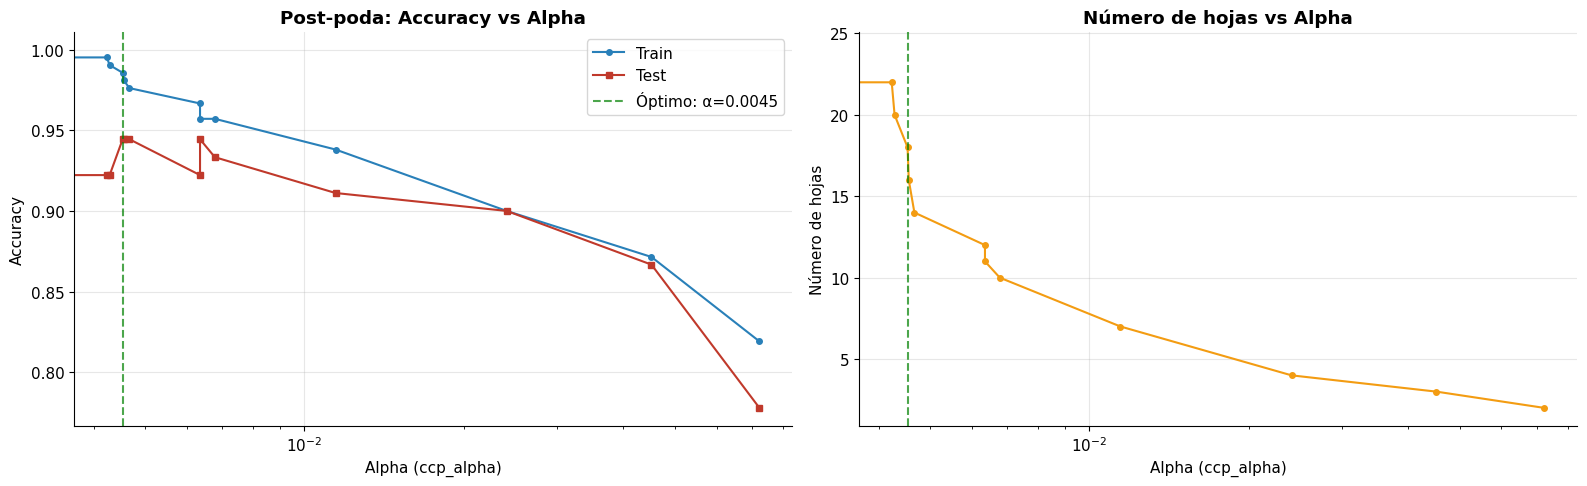


🌳 Mejor alpha: 0.004535
   Accuracy en test: 94.44%
   Número de hojas: 18


In [7]:
# Determinar alpha óptimo usando validación cruzada
tree = DecisionTreeClassifier(random_state=42)
path = tree.cost_complexity_pruning_path(X_tr, y_tr)
alphas = path.ccp_alphas[:-1]  # excluir el último (árbol con 1 nodo)

print(f"Número de valores de alpha generados: {len(alphas)}")
print(f"Rango de alpha: [{alphas.min():.6f}, {alphas.max():.6f}]")

# Probar diferentes alphas con CV
train_scores, test_scores = [], []
n_leaves = []

for alpha in alphas:
    tree = DecisionTreeClassifier(ccp_alpha=alpha, random_state=42)
    tree.fit(X_tr, y_tr)
    train_scores.append(tree.score(X_tr, y_tr))
    test_scores.append(tree.score(X_te, y_te))
    n_leaves.append(tree.get_n_leaves())

# Visualizar
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

axes[0].plot(alphas, train_scores, 'o-', color='#2980B9', label='Train', markersize=4)
axes[0].plot(alphas, test_scores, 's-', color='#C0392B', label='Test', markersize=4)
axes[0].set_xscale('log')
axes[0].set_xlabel('Alpha (ccp_alpha)')
axes[0].set_ylabel('Accuracy')
axes[0].set_title('Post-poda: Accuracy vs Alpha', fontweight='bold')
axes[0].legend()
axes[0].grid(alpha=0.3)

# Marcar el óptimo
best_idx = np.argmax(test_scores)
best_alpha = alphas[best_idx]
axes[0].axvline(x=best_alpha, color='green', linestyle='--', alpha=0.7,
                label=f'Óptimo: α={best_alpha:.4f}')
axes[0].legend()

axes[1].plot(alphas, n_leaves, 'o-', color='#F39C12', markersize=4)
axes[1].set_xscale('log')
axes[1].set_xlabel('Alpha (ccp_alpha)')
axes[1].set_ylabel('Número de hojas')
axes[1].set_title('Número de hojas vs Alpha', fontweight='bold')
axes[1].axvline(x=best_alpha, color='green', linestyle='--', alpha=0.7)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print(f"\n🌳 Mejor alpha: {best_alpha:.6f}")
print(f"   Accuracy en test: {test_scores[best_idx]*100:.2f}%")
print(f"   Número de hojas: {n_leaves[best_idx]}")

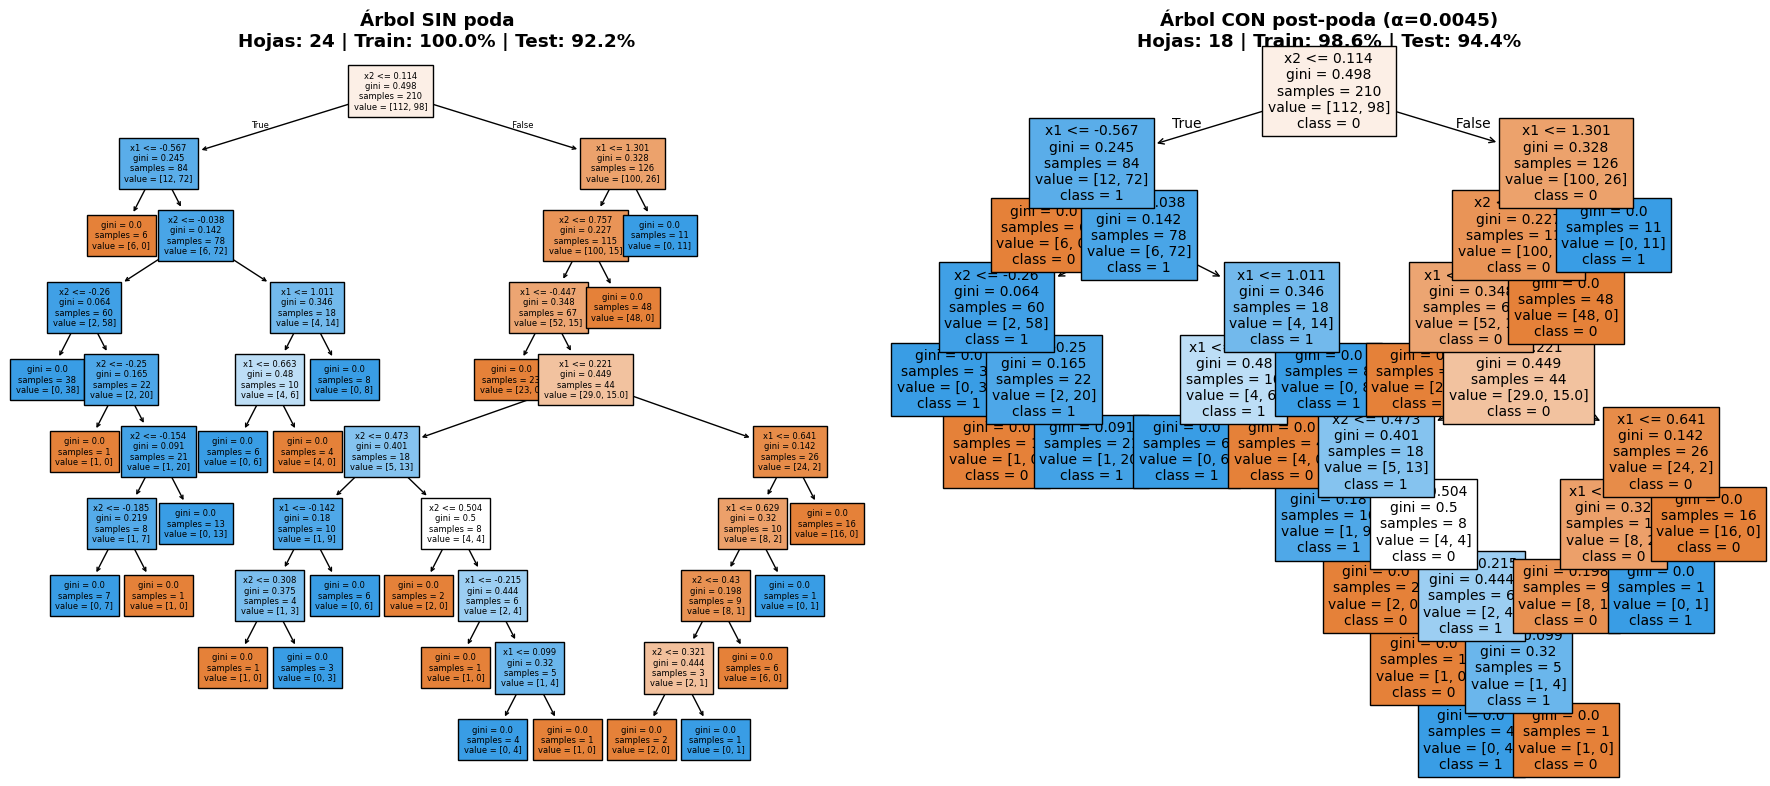

In [8]:
# Comparar árbol completo vs árbol podado
tree_full = DecisionTreeClassifier(random_state=42).fit(X_tr, y_tr)
tree_pruned = DecisionTreeClassifier(ccp_alpha=best_alpha, random_state=42).fit(X_tr, y_tr)

fig, axes = plt.subplots(1, 2, figsize=(18, 8))

# Árbol completo (truncado a visualización)
plot_tree(tree_full, filled=True, fontsize=6, ax=axes[0],
          feature_names=['x1', 'x2'])
axes[0].set_title(f'Árbol SIN poda\nHojas: {tree_full.get_n_leaves()} | Train: {tree_full.score(X_tr, y_tr)*100:.1f}% | Test: {tree_full.score(X_te, y_te)*100:.1f}%',
                  fontweight='bold')

# Árbol podado
plot_tree(tree_pruned, filled=True, fontsize=10, ax=axes[1],
          feature_names=['x1', 'x2'], class_names=['0', '1'])
axes[1].set_title(f'Árbol CON post-poda (α={best_alpha:.4f})\nHojas: {tree_pruned.get_n_leaves()} | Train: {tree_pruned.score(X_tr, y_tr)*100:.1f}% | Test: {tree_pruned.score(X_te, y_te)*100:.1f}%',
                  fontweight='bold')

plt.tight_layout()
plt.show()

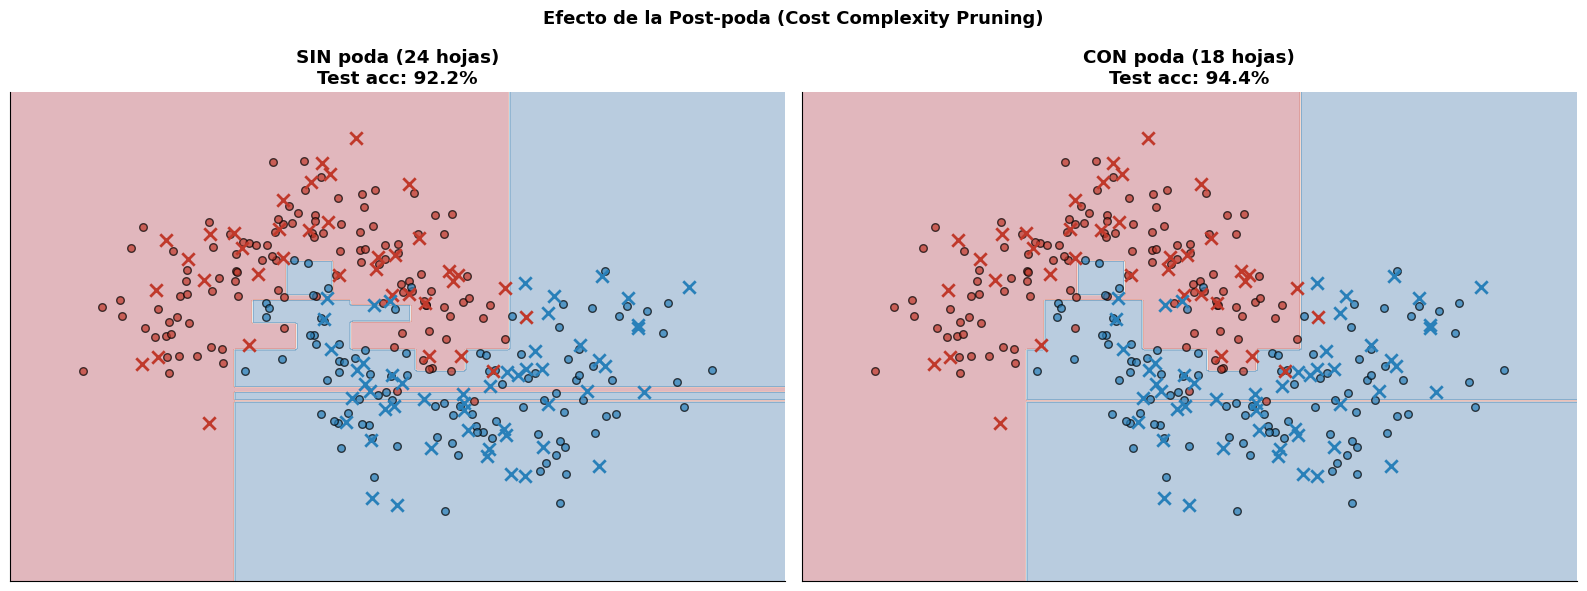

In [9]:
# Visualizar fronteras: sin poda vs con poda
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
xx, yy = np.meshgrid(np.linspace(X_tr[:,0].min()-0.5, X_tr[:,0].max()+0.5, 300),
                     np.linspace(X_tr[:,1].min()-0.5, X_tr[:,1].max()+0.5, 300))

for ax, (tree, title) in zip(axes, [
    (tree_full, f'SIN poda ({tree_full.get_n_leaves()} hojas)'),
    (tree_pruned, f'CON poda ({tree_pruned.get_n_leaves()} hojas)')
]):
    Z = tree.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.3, cmap='RdBu')
    ax.scatter(X_tr[y_tr==0, 0], X_tr[y_tr==0, 1], c='#C0392B', s=30, edgecolor='k', alpha=0.7)
    ax.scatter(X_tr[y_tr==1, 0], X_tr[y_tr==1, 1], c='#2980B9', s=30, edgecolor='k', alpha=0.7)
    ax.scatter(X_te[y_te==0, 0], X_te[y_te==0, 1], c='#C0392B', s=80, marker='x', linewidth=2)
    ax.scatter(X_te[y_te==1, 0], X_te[y_te==1, 1], c='#2980B9', s=80, marker='x', linewidth=2)
    ax.set_title(f'{title}\nTest acc: {tree.score(X_te, y_te)*100:.1f}%', fontweight='bold')
    ax.set_xticks([]); ax.set_yticks([])

plt.suptitle('Efecto de la Post-poda (Cost Complexity Pruning)', fontweight='bold', fontsize=13)
plt.tight_layout()
plt.show()

## 7. Importancia de Características

Los árboles calculan la **importancia de cada característica** basándose en cuánto reduce la impureza en todas las divisiones que la usan.

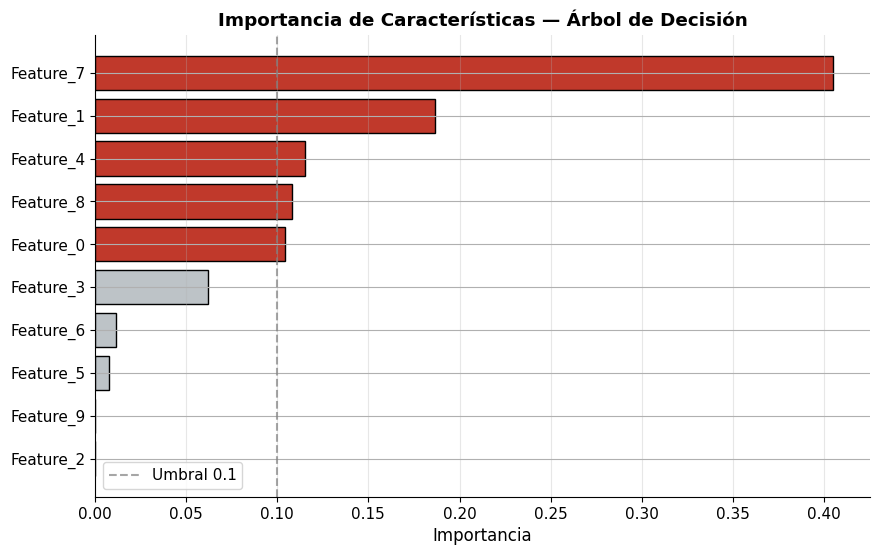

📊 IMPORTANCIA DE CARACTERÍSTICAS
  Feature  Importancia
Feature_7     0.404953
Feature_1     0.186829
Feature_4     0.115195
Feature_8     0.107952
Feature_0     0.104183
Feature_3     0.061929
Feature_6     0.011375
Feature_5     0.007583
Feature_9     0.000000
Feature_2     0.000000

💡 Las 4 features informativas fueron detectadas como las más importantes


In [10]:
# Dataset con más features para análisis de importancia
X_imp, y_imp = make_classification(
    n_samples=500, n_features=10, n_informative=4,
    n_redundant=3, n_classes=2, random_state=42
)
feature_names = [f'Feature_{i}' for i in range(10)]

X_tr_i, X_te_i, y_tr_i, y_te_i = train_test_split(X_imp, y_imp, test_size=0.3, random_state=42)

tree_imp = DecisionTreeClassifier(max_depth=5, random_state=42)
tree_imp.fit(X_tr_i, y_tr_i)

# Importancias
importancias = pd.DataFrame({
    'Feature': feature_names,
    'Importancia': tree_imp.feature_importances_
}).sort_values('Importancia', ascending=True)

plt.figure(figsize=(10, 6))
colors = ['#C0392B' if imp > 0.1 else '#BDC3C7' for imp in importancias['Importancia']]
plt.barh(importancias['Feature'], importancias['Importancia'], color=colors, edgecolor='k')
plt.xlabel('Importancia', fontsize=12)
plt.title('Importancia de Características — Árbol de Decisión', fontweight='bold')
plt.axvline(x=0.1, color='gray', linestyle='--', alpha=0.7, label='Umbral 0.1')
plt.legend()
plt.grid(alpha=0.3, axis='x')
plt.show()

print("="*80)
print("📊 IMPORTANCIA DE CARACTERÍSTICAS")
print("="*80)
print(importancias.sort_values('Importancia', ascending=False).to_string(index=False))
print("\n💡 Las 4 features informativas fueron detectadas como las más importantes")

## 8. Resumen Comparativo: Todos los Datasets

Tabla resumen con las mejores configuraciones para cada dataset.

In [11]:
# Resumen: mejor configuración por dataset
resultados_finales = []

for nombre, (X, y) in datasets.items():
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, random_state=42)
    
    # Sin poda
    tree_full = DecisionTreeClassifier(random_state=42).fit(X_tr, y_tr)
    
    # Pre-poda óptima
    grid_small = GridSearchCV(
        DecisionTreeClassifier(random_state=42),
        {'max_depth': [2, 3, 5, 7, 10], 'min_samples_leaf': [1, 2, 5]},
        cv=3, scoring='accuracy', n_jobs=-1
    )
    grid_small.fit(X_tr, y_tr)
    tree_pre = grid_small.best_estimator_
    
    resultados_finales.append({
        'Dataset': nombre,
        'Sin poda (Train)': tree_full.score(X_tr, y_tr),
        'Sin poda (Test)': tree_full.score(X_te, y_te),
        'Pre-poda (Test)': tree_pre.score(X_te, y_te),
        'Hojas sin poda': tree_full.get_n_leaves(),
        'Hojas con poda': tree_pre.get_n_leaves(),
        'Mejores params': str(grid_small.best_params_)
    })

df_final = pd.DataFrame(resultados_finales)

print("="*80)
print("📊 RESUMEN: EFECTO DE LA PODA EN TODOS LOS DATASETS")
print("="*80)
for _, row in df_final.iterrows():
    print(f"\n📁 {row['Dataset']}")
    print(f"   Sin poda:  Train={row['Sin poda (Train)']*100:.1f}%, Test={row['Sin poda (Test)']*100:.1f}%, Hojas={row['Hojas sin poda']}")
    print(f"   Con poda:  Test={row['Pre-poda (Test)']*100:.1f}%, Hojas={row['Hojas con poda']}")
    print(f"   Params: {row['Mejores params']}")

📊 RESUMEN: EFECTO DE LA PODA EN TODOS LOS DATASETS

📁 Moons
   Sin poda:  Train=100.0%, Test=92.2%, Hojas=24
   Con poda:  Test=90.0%, Hojas=19
   Params: {'max_depth': 7, 'min_samples_leaf': 1}

📁 Circles
   Sin poda:  Train=100.0%, Test=93.3%, Hojas=19
   Con poda:  Test=93.3%, Hojas=16
   Params: {'max_depth': 7, 'min_samples_leaf': 1}

📁 Blobs
   Sin poda:  Train=100.0%, Test=100.0%, Hojas=2
   Con poda:  Test=100.0%, Hojas=2
   Params: {'max_depth': 2, 'min_samples_leaf': 1}

📁 XOR
   Sin poda:  Train=100.0%, Test=93.3%, Hojas=15
   Con poda:  Test=54.4%, Hojas=9
   Params: {'max_depth': 5, 'min_samples_leaf': 1}

📁 Spiral
   Sin poda:  Train=100.0%, Test=81.7%, Hojas=35
   Con poda:  Test=81.7%, Hojas=30
   Params: {'max_depth': 10, 'min_samples_leaf': 1}


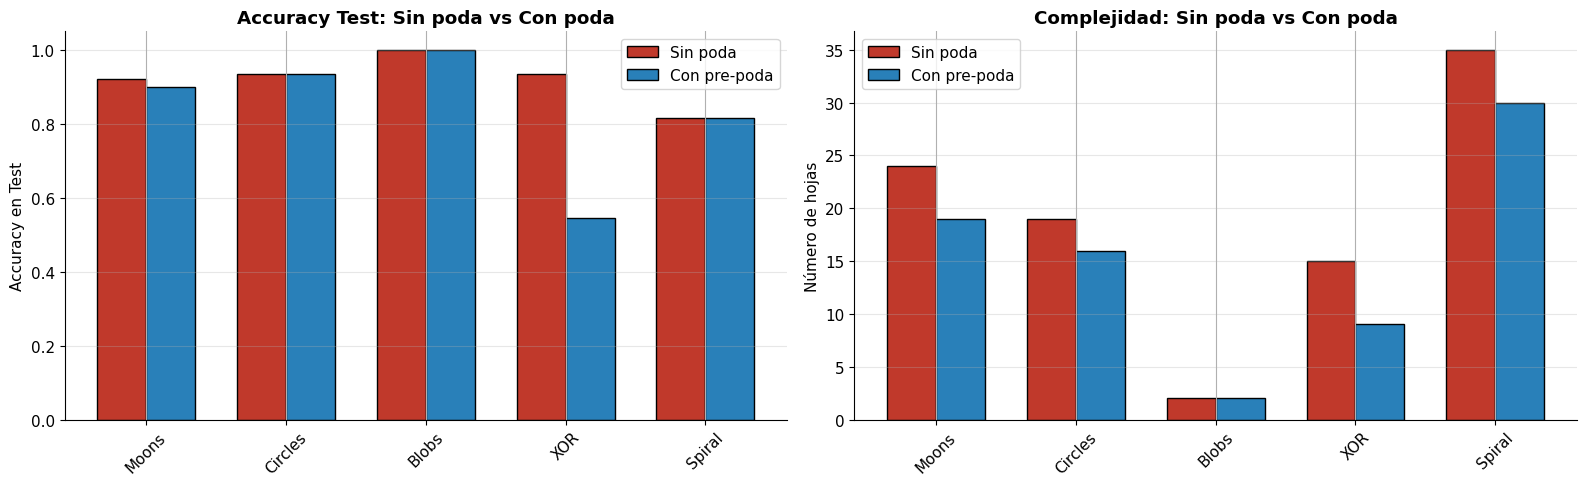

In [12]:
# Visualización del resumen
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

x = np.arange(len(df_final))
width = 0.35

axes[0].bar(x - width/2, df_final['Sin poda (Test)'], width, label='Sin poda', color='#C0392B', edgecolor='k')
axes[0].bar(x + width/2, df_final['Pre-poda (Test)'], width, label='Con pre-poda', color='#2980B9', edgecolor='k')
axes[0].set_xticks(x)
axes[0].set_xticklabels(df_final['Dataset'], rotation=45)
axes[0].set_ylabel('Accuracy en Test')
axes[0].set_title('Accuracy Test: Sin poda vs Con poda', fontweight='bold')
axes[0].legend()
axes[0].grid(alpha=0.3, axis='y')

axes[1].bar(x - width/2, df_final['Hojas sin poda'], width, label='Sin poda', color='#C0392B', edgecolor='k')
axes[1].bar(x + width/2, df_final['Hojas con poda'], width, label='Con pre-poda', color='#2980B9', edgecolor='k')
axes[1].set_xticks(x)
axes[1].set_xticklabels(df_final['Dataset'], rotation=45)
axes[1].set_ylabel('Número de hojas')
axes[1].set_title('Complejidad: Sin poda vs Con poda', fontweight='bold')
axes[1].legend()
axes[1].grid(alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

## 9. Ejercicios Propuestos

### Ejercicio 1: Kernel Trick vs Árboles

Entrena un SVM con kernel RBF en el dataset `Spiral` y compáralo con un árbol de decisión. ¿Cuál funciona mejor? ¿Por qué?

### Ejercicio 2: Poda por Profundidad vs Poda por Alpha

Genera un dataset ruidoso y compara:
- Pre-poda con `max_depth` óptimo
- Post-poda con `ccp_alpha` óptimo

¿Cuál da mejor accuracy en test?

### Ejercicio 3: Árbol de Regresión

Usa `DecisionTreeRegressor` para ajustar la función $y = \sin(x) + \text{ruido}$. Analiza el efecto de la profundidad en el sobreajuste.

### Ejercicio 4: Estabilidad del Árbol

Entrena 100 árboles con diferentes `random_state`. Mide la varianza en accuracy de test. Compara con el promedio de 100 árboles (precursor de Random Forest).

🔬 SOLUCIÓN Ejercicio 1: SVM vs Árbol en Spiral
SVM RBF accuracy: 85.00%
Árbol accuracy:   81.67%

💡 El SVM funciona mejor porque captura relaciones curvas suaves,
   mientras que el árbol necesita muchos cortes ortogonales para
   aproximar la espiral, lo que genera muchas hojas y sobreajuste.


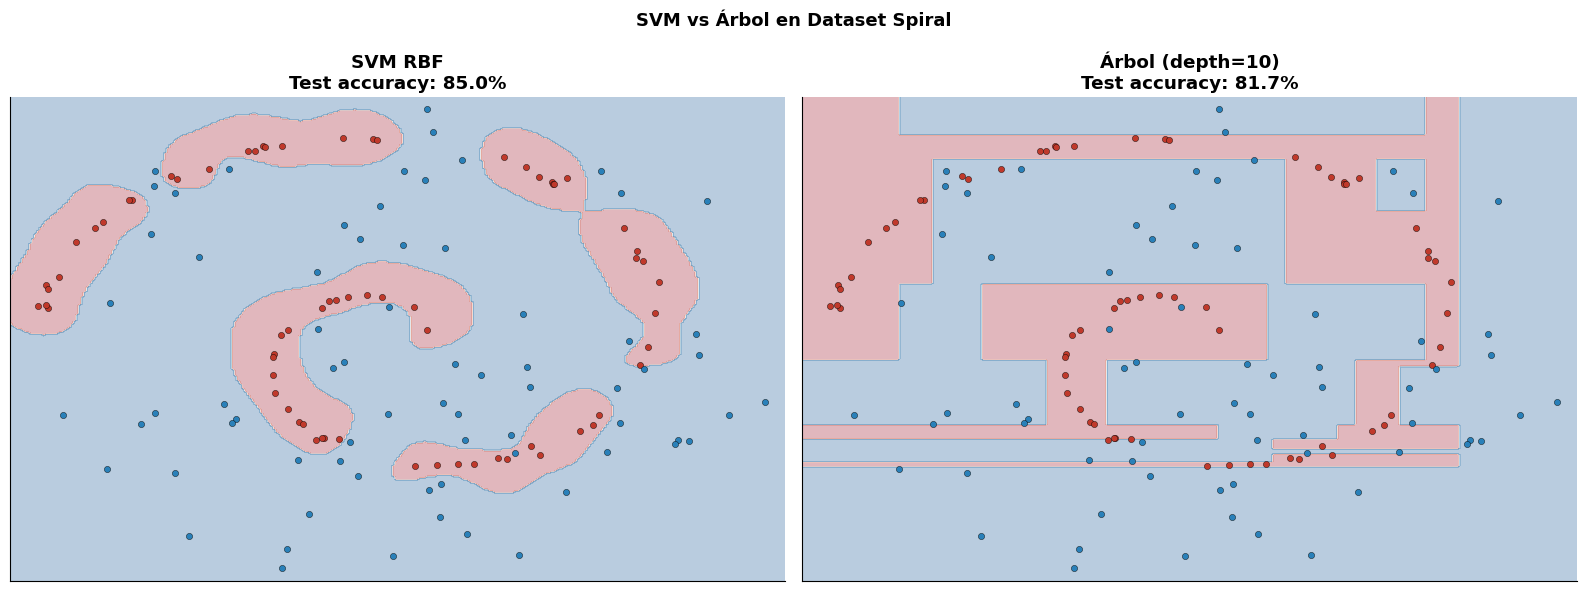

In [13]:
# SOLUCIÓN Ejercicio 1: SVM vs Árbol en Spiral
from sklearn.svm import SVC

X_spiral, y_spiral = datasets['Spiral']
X_tr_s, X_te_s, y_tr_s, y_te_s = train_test_split(X_spiral, y_spiral, test_size=0.3, random_state=42)

# SVM con RBF
svm = SVC(kernel='rbf', C=10, gamma=1.0, random_state=42)
svm.fit(X_tr_s, y_tr_s)
acc_svm = svm.score(X_te_s, y_te_s)

# Árbol
tree = DecisionTreeClassifier(max_depth=10, random_state=42)
tree.fit(X_tr_s, y_tr_s)
acc_tree = tree.score(X_te_s, y_te_s)

print("="*80)
print("🔬 SOLUCIÓN Ejercicio 1: SVM vs Árbol en Spiral")
print("="*80)
print(f"SVM RBF accuracy: {acc_svm*100:.2f}%")
print(f"Árbol accuracy:   {acc_tree*100:.2f}%")
print(f"\n💡 El SVM funciona mejor porque captura relaciones curvas suaves,")
print(f"   mientras que el árbol necesita muchos cortes ortogonales para")
print(f"   aproximar la espiral, lo que genera muchas hojas y sobreajuste.")

# Visualización
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
xx, yy = np.meshgrid(np.linspace(X_spiral[:,0].min()-0.5, X_spiral[:,0].max()+0.5, 300),
                     np.linspace(X_spiral[:,1].min()-0.5, X_spiral[:,1].max()+0.5, 300))

for ax, (model, name, acc) in zip(axes, [(svm, 'SVM RBF', acc_svm), (tree, 'Árbol (depth=10)', acc_tree)]):
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.3, cmap='RdBu')
    ax.scatter(X_tr_s[y_tr_s==0, 0], X_tr_s[y_tr_s==0, 1], c='#C0392B', s=20, edgecolor='k', linewidth=0.3)
    ax.scatter(X_tr_s[y_tr_s==1, 0], X_tr_s[y_tr_s==1, 1], c='#2980B9', s=20, edgecolor='k', linewidth=0.3)
    ax.set_title(f'{name}\nTest accuracy: {acc*100:.1f}%', fontweight='bold')
    ax.set_xticks([]); ax.set_yticks([])

plt.suptitle('SVM vs Árbol en Dataset Spiral', fontweight='bold', fontsize=13)
plt.tight_layout()
plt.show()

## 10. Conclusiones

### Lecciones clave

1. **Árboles vs otros modelos:** Los árboles crean fronteras **ortogonales** (paralelas a los ejes). Esto los hace ideales para datos tabulares pero limitados para fronteras diagonales o curvas.

2. **Gini vs Entropía:** Ambas métricas dan resultados **similares** en la práctica. Gini es ligeramente más rápida computacionalmente, mientras que Entropía tiene una base teórica más sólida (teoría de la información).

3. **Sobreajuste:** Sin poda, los árboles crecen hasta memorizar los datos. La accuracy en train llega al 100% pero en test cae.

4. **Pre-poda:** Limitar `max_depth`, `min_samples_split` y `min_samples_leaf` es la forma más simple y efectiva de prevenir sobreajuste.

5. **Post-poda (CCP):** El parámetro `ccp_alpha` controla el trade-off entre complejidad y precisión. Es más sofisticado que la pre-poda.

6. **Interpretabilidad:** La **importancia de características** permite saber cuáles variables son más relevantes para la decisión.

### Próximos pasos

En el siguiente notebook aplicaremos estos conceptos al **dataset de rendimiento académico** con la variable `Remontada`, comparando árboles con los modelos anteriores (Regresión Logística, SVM, SVD+SVM).